In [4]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy


plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 15,
    'axes.labelsize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 25
})

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.filtering import iterative_filtering1D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir
RESULTS = results_dir("paper1_methods")

In [5]:
#Function Definitions
def partial_x_2d(f,dx):
    """Compute ∂f/∂x using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dx = np.zeros_like(f)
    
    # Central difference in x-direction (axis=0)
    df_dx[1:Nx-1, :] = (f[2:Nx, :] - f[0:Nx-2, :]) / (2 * dx)
    
    # Periodic boundaries (x-direction)
    df_dx[0, :] = (f[1, :] - f[-1, :]) / (2 * dx)
    df_dx[-1, :] = (f[0, :] - f[-2, :]) / (2 * dx)
    
    return df_dx

def partial_y_2d(f,dy):
    """Compute ∂f/∂y using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dy = np.zeros_like(f)
    
    # Central difference in y-direction (axis=1)
    df_dy[:, 1:Ny-1] = (f[:, 2:Ny] - f[:, 0:Ny-2]) / (2 * dy)
    
    # Periodic boundaries (y-direction)
    df_dy[:, 0] = (f[:, 1] - f[:, -1]) / (2 * dy)
    df_dy[:, -1] = (f[:, 0] - f[:, -2]) / (2 * dy)
    
    return df_dy

def partial_x_fft(f, dx):
    """
    Calculate ∂f/∂x using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dx (float): Grid spacing in the x-direction.

    Returns:
        df_dx (2D np.array): Partial derivative ∂f/∂x.
    """
    nx, ny = f.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi  # Wavenumbers in x
    kx = kx[:, np.newaxis]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dx_hat = 1j * kx * f_hat
    df_dx = np.fft.ifft2(df_dx_hat).real

    return np.array(df_dx)

def partial_y_fft(f, dy):
    """
    Calculate ∂f/∂y using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dy (float): Grid spacing in the y-direction.

    Returns:
        df_dy (2D np.array): Partial derivative ∂f/∂y.
    """
    nx, ny = f.shape
    ky = np.fft.fftfreq(ny, d=dy) * 2 * np.pi  # Wavenumbers in y
    ky = ky[np.newaxis, :]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dy_hat = 1j * ky * f_hat
    df_dy = np.fft.ifft2(df_dy_hat).real

    return df_dy

def index_of_just_smaller(arr, value):
    arr = np.asarray(arr)
    mask = arr < value
    if not np.any(mask):
        return None  # No smaller value exists
    return np.argmax(np.where(mask, arr, -np.inf))



dx = 0.0625
dy = 0.0625

In [6]:
#Lets Plot J_Parallel

File_Bx = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bx_ApJ_t40.h5'
File_By = f'{DATA_ROOT}/beta_p_1/beta_e_1/By_ApJ_t40.h5'


with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

data_Bx = iterative_filtering1D(data_Bx, 2)
data_By = iterative_filtering1D(data_By, 2)

#Compute J_parallel using Fourier Transform
J_par_FT = partial_x_fft(data_By,dx)-partial_y_fft(data_Bx,dy)
J_par_mod = np.abs(J_par_FT)

Nx, Ny = J_par_mod.shape

Lx = Nx * dx
Ly = Ny * dy

dx = dy = 0.0625

Nx, Ny = J_par_mod.shape

extent = [0, Nx*dx, 0, Ny*dy]

plt.figure(figsize=(10, 8))

img = plt.imshow(
    J_par_mod,
    cmap='inferno',
    vmin=0,
    vmax=0.5,
    extent=extent
)

plt.colorbar(img)

plt.title(r'$|J_\parallel|$', fontsize=25)
plt.xlabel(r'$x/d_p$', fontsize=20)
plt.ylabel(r'$y/d_p$', fontsize=20)

plt.tight_layout()
plt.savefig(RESULTS / 'Jpar40.png', dpi=300)
plt.show()

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/home/UNN/w24021992/NAS/simulations_beta_scan/beta_p_1/beta_e_1/Bx_ApJ_t40.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

IMF 1
IMF 2
IMF 3
IMF 4
(5, 4096, 4096)
IMF 1
IMF 2
IMF 3
IMF 4
(5, 4096, 4096)


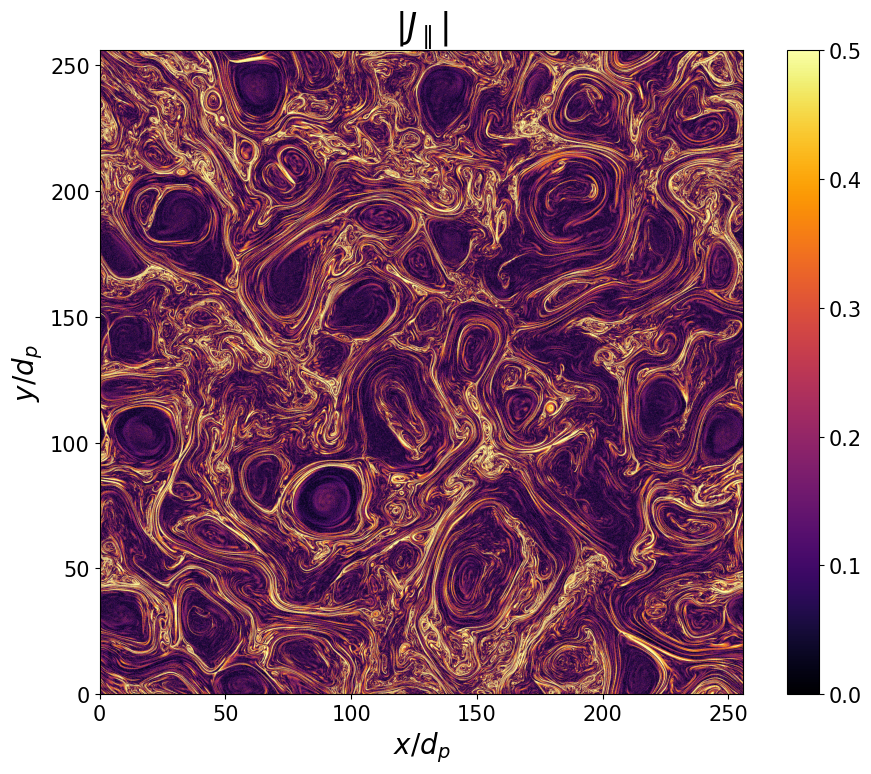

In [53]:
#Lets Plot J_Parallel

File_Bx = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bx_ApJ_t200.h5'
File_By = f'{DATA_ROOT}/beta_p_1/beta_e_1/By_ApJ_t200.h5'


with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

data_Bx = iterative_filtering1D(data_Bx, 2)
data_By = iterative_filtering1D(data_By, 2)

#Compute J_parallel using Fourier Transform
J_par_FT = partial_x_fft(data_By,dx)-partial_y_fft(data_Bx,dy)
J_par_mod = np.abs(J_par_FT)

Nx, Ny = J_par_mod.shape

Lx = Nx * dx
Ly = Ny * dy

dx = dy = 0.0625

Nx, Ny = J_par_mod.shape

extent = [0, Nx*dx, 0, Ny*dy]

plt.figure(figsize=(10, 8))

img = plt.imshow(
    J_par_mod,
    cmap='inferno',
    vmin=0,
    vmax=0.5,
    extent=extent
)

plt.colorbar(img)

plt.title(r'$|J_\parallel|$', fontsize=25)
plt.xlabel(r'$x/d_p$', fontsize=20)
plt.ylabel(r'$y/d_p$', fontsize=20)

plt.tight_layout()
plt.savefig(RESULTS / 'Jpar200.png', dpi=300)
plt.show()

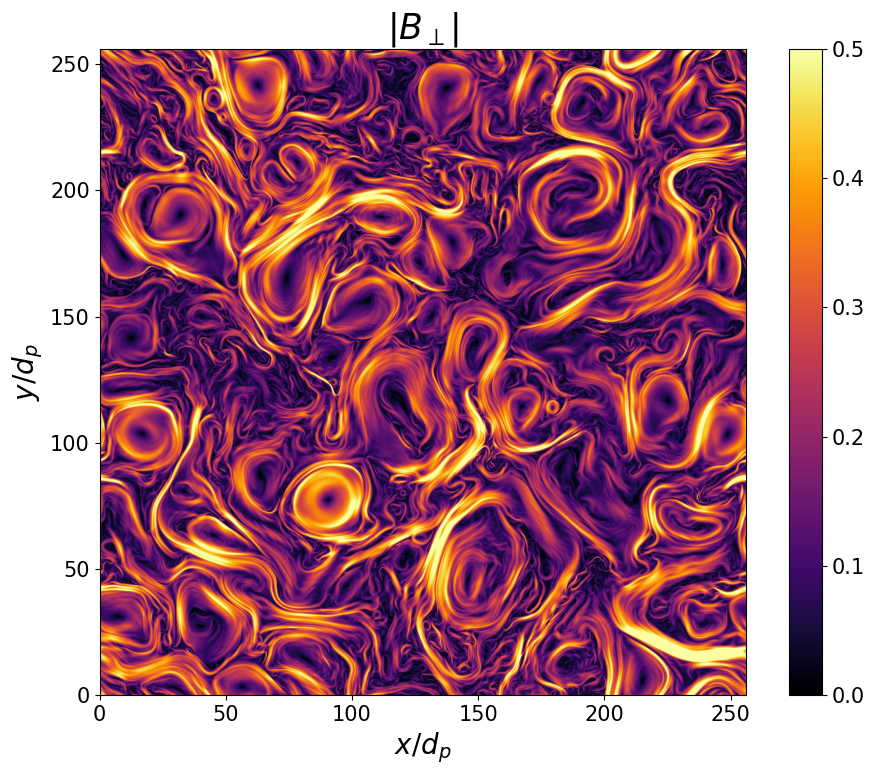

In [13]:
#Lets Plot J_Parallel

File_Bx = f'{NAS_ROOT}/DATA/Brms_0.24/beta_p_1/beta_e_1/Bx_ApJ_t200.h5'
File_By = f'{NAS_ROOT}/DATA/Brms_0.24/beta_p_1/beta_e_1/By_ApJ_t200.h5'


with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

#Compute J_parallel using Fourier Transform
B_perp = np.sqrt(data_Bx**2 + data_By**2)

Nx, Ny = B_perp.shape

Lx = Nx * dx
Ly = Ny * dy

dx = dy = 0.0625

Nx, Ny = B_perp.shape

extent = [0, Nx*dx, 0, Ny*dy]

plt.figure(figsize=(10, 8))

img = plt.imshow(
    B_perp,
    cmap='inferno',
    vmin=0,
    vmax=0.5,
    extent=extent
)

plt.colorbar(img)

plt.title(r'$|B_\perp|$', fontsize=25)
plt.xlabel(r'$x/d_p$', fontsize=20)
plt.ylabel(r'$y/d_p$', fontsize=20)

plt.tight_layout()
plt.savefig(RESULTS / 'Bperp_40.png', dpi=300)
plt.show()

orientation fixed via div B (rms 8.75e-02 vs 2.73e-01)
window 32 d_p = 512 cells -> 1536 px; computing LIC ...
saved Jpar_LIC_t200_art.png (1536 x 1536 px) and Jpar_LIC_t200_check.png in 30 s


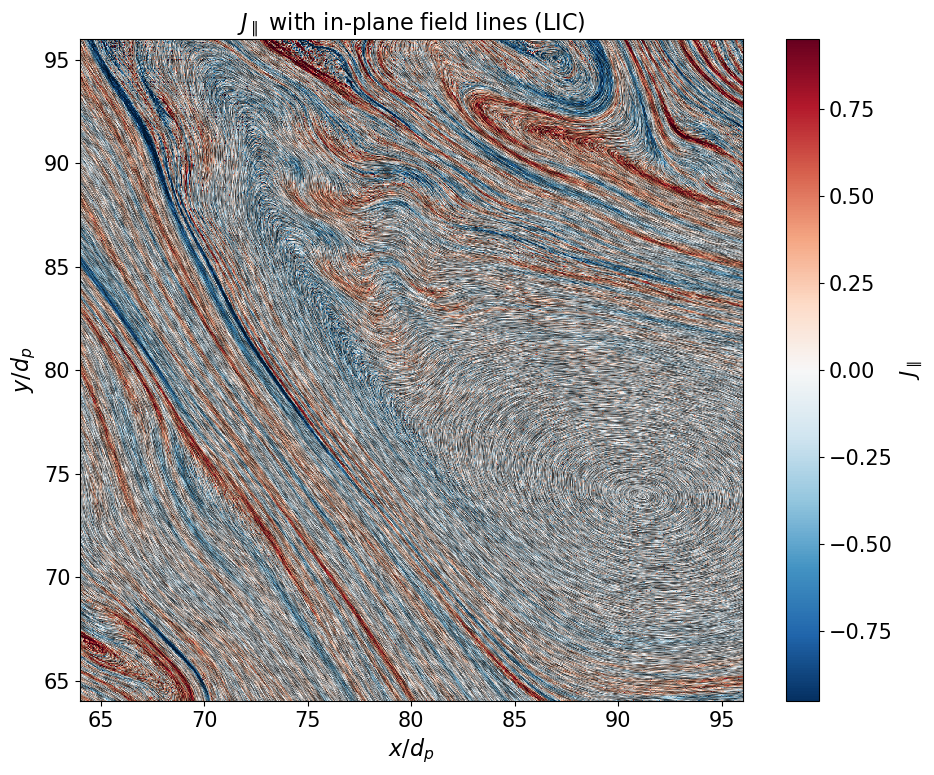

In [15]:
"""
LIC (line integral convolution) image of the in-plane magnetic field lines,
coloured by J_parallel (or J_z).

Field lines come from Bx, By only. If FILE_BZ is given the colour is the true
J_parallel = J.B/|B|; otherwise J_z = dBy/dx - dBx/dy is used (with B0 out of
plane, J_parallel ~ J_z anyway).

Outputs
  <OUT>_art.png      full-bleed image, no axes, 300 dpi metadata (competition)
  <OUT>_check.png    same image with axes and colourbar (for checking)
"""
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from scipy.ndimage import map_coordinates

# ------------------------------------------------------------------ settings
RUN = f"{NAS_ROOT}/DATA/Brms_0.24/beta_p_1/beta_e_1/"
FILE_BX = RUN + "Bx_ApJ_t200.h5"
FILE_BY = RUN + "By_ApJ_t200.h5"
FILE_BZ = RUN + "Bz_ApJ_t200.h5"   # set to None to colour by J_z instead
dx = 0.0625                          # cell size [d_p]

# region to draw (in d_p); the full box is 256 x 256 d_p
X0, Y0 = 64.0, 64.0                  # lower-left corner
SIZE = 32.0                          # side length; 64 d_p = 1024 cells

OVERSAMPLE = 3        # output pixels per cell: 1024 cells -> 3072 px (~10 in at 300 dpi)
LENGTH = 30           # streak half-length in output pixels (longer = smoother lines)
STEP = 0.5            # integration step in output pixels
CMAP = "RdBu_r"       # diverging; try "berlin" (dark centre, matplotlib >= 3.10)
CLIP_PCT = 99.5       # colour range = this percentile of |J|
TEXTURE = 0.75        # 0 = flat colour, 1 = strongest field-line texture
OUT = str(RESULTS / "Jpar_LIC_t200")
SEED = 1
# ------------------------------------------------------------------------------


def deriv(f, d, axis):
    n = f.shape[axis]
    k = 2 * np.pi * np.fft.fftfreq(n, d=d)
    shape = [1] * f.ndim
    shape[axis] = n
    return np.real(np.fft.ifft(1j * k.reshape(shape) * np.fft.fft(f, axis=axis), axis=axis))


def read(fn):
    with h5py.File(fn, "r") as f:
        return f["DS1"][:].T.astype(np.float64)


def sample(arr, r, c, mode):
    try:
        return map_coordinates(arr, [r, c], order=1, mode=mode)
    except RuntimeError:  # older scipy without 'grid-wrap'
        return map_coordinates(arr, [r, c], order=1, mode="wrap")


def lic(ux, uy, row0, col0, n_cells, f, length, step, seed):
    """LIC texture for a square window of the periodic unit-vector field (ux, uy).

    ux, uy : field direction along columns (x) and rows (y) of the full arrays
    row0, col0, n_cells : window position and size in cells
    f : output pixels per cell
    """
    npx = n_cells * f
    margin = int(np.ceil(length * step)) + 2
    rng = np.random.default_rng(seed)
    noise = rng.random((npx + 2 * margin, npx + 2 * margin))

    R0, C0 = np.mgrid[0:npx, 0:npx].astype(np.float64)
    acc = noise[margin:-margin, margin:-margin].copy()
    wsum = np.ones_like(acc)
    for sign in (1.0, -1.0):
        R, C = R0.copy(), C0.copy()
        for k in range(1, length + 1):
            # RK2 (midpoint) step along the field line, in output pixels
            fr, fc = row0 + R / f, col0 + C / f
            vy1, vx1 = sample(uy, fr, fc, "grid-wrap"), sample(ux, fr, fc, "grid-wrap")
            fr, fc = row0 + (R + 0.5 * sign * step * vy1) / f, col0 + (C + 0.5 * sign * step * vx1) / f
            vy2, vx2 = sample(uy, fr, fc, "grid-wrap"), sample(ux, fr, fc, "grid-wrap")
            R += sign * step * vy2
            C += sign * step * vx2
            w = 0.5 * (1 + np.cos(np.pi * k / (length + 1)))  # Hann weight
            acc += w * sample(noise, R + margin, C + margin, "nearest")
            wsum += w
    return acc / wsum


def main():
    t_start = time.time()
    bx, by = read(FILE_BX), read(FILE_BY)
    bz = read(FILE_BZ) if FILE_BZ else None

    # put x along columns and y along rows (decided by div B = 0)
    div_a = np.std(deriv(bx, dx, 0) + deriv(by, dx, 1))
    div_b = np.std(deriv(bx, dx, 1) + deriv(by, dx, 0))
    if div_a < div_b:  # x is currently along rows -> transpose
        bx, by = bx.T, by.T
        bz = bz.T if bz is not None else None
    print(f"orientation fixed via div B (rms {min(div_a, div_b):.2e} vs {max(div_a, div_b):.2e})")

    # colour quantity
    jz = deriv(by, dx, 1) - deriv(bx, dx, 0)
    if bz is not None:
        jx, jy = deriv(bz, dx, 0), -deriv(bz, dx, 1)
        bmag = np.sqrt(bx ** 2 + by ** 2 + bz ** 2)
        J = (jx * bx + jy * by + jz * bz) / bmag
        label = r"$J_\parallel$"
        del jx, jy, bmag
    else:
        J = jz
        label = r"$J_z$"

    # in-plane field direction
    bperp = np.hypot(bx, by) + 1e-30
    ux, uy = bx / bperp, by / bperp

    n = int(round(SIZE / dx))
    row0, col0 = int(round(Y0 / dx)), int(round(X0 / dx))
    print(f"window {SIZE:g} d_p = {n} cells -> {n * OVERSAMPLE} px; computing LIC ...", flush=True)
    tex = lic(ux, uy, row0, col0, n, OVERSAMPLE, LENGTH, STEP, SEED)

    # contrast-stretch the texture to [0, 1]
    lo, hi = np.percentile(tex, [1, 99])
    tex = np.clip((tex - lo) / (hi - lo), 0, 1)

    # colour on the output grid
    npx = n * OVERSAMPLE
    R, C = np.mgrid[0:npx, 0:npx].astype(np.float64)
    Jw = sample(J, row0 + (R + 0.5) / OVERSAMPLE - 0.5, col0 + (C + 0.5) / OVERSAMPLE - 0.5, "grid-wrap")
    vmax = np.percentile(np.abs(Jw), CLIP_PCT)
    norm = Normalize(-vmax, vmax)
    rgb = plt.get_cmap(CMAP)(norm(Jw))[..., :3]
    shade = (1 - TEXTURE) + TEXTURE * tex
    img = np.clip(rgb * shade[..., None], 0, 1)

    plt.imsave(f"{OUT}_art.png", img, origin="lower", dpi=300)

    extent = [X0, X0 + SIZE, Y0, Y0 + SIZE]
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(img, origin="lower", extent=extent, interpolation="none")
    sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
    fig.colorbar(sm, ax=ax, label=label)
    ax.set_xlabel(r"$x/d_p$", fontsize=16)
    ax.set_ylabel(r"$y/d_p$", fontsize=16)
    ax.set_title(f"{label} with in-plane field lines (LIC)", fontsize=16)
    fig.tight_layout()
    fig.savefig(f"{OUT}_check.png", dpi=200)
    print(f"saved {OUT}_art.png ({npx} x {npx} px) and {OUT}_check.png "
          f"in {time.time() - t_start:.0f} s")


if __name__ == "__main__":
    main()